# Capstone Walkthrough: Profit-Driven Customer Churn Prediction

**RabTech Academy · Data Science with Python & R Internship · Task 6**
Author: Dheena Dhayalan P

This notebook walks through the capstone workflow step by step. The heavy computation (model
tuning, bootstrapping) is done by the reproducible pipeline in `src/churn/`. This notebook loads
its output (`reports/metrics.json` and the figures) and explains each result. The full write-up
is in [`reports/capstone_report.pdf`](../reports/capstone_report.pdf).

| File | Role |
|---|---|
| `docs/analysis_plan.md` | Research questions, hypotheses and methods, **committed before modelling** |
| `src/churn/data.py` | Loading, validation, cleaning, feature engineering |
| `src/churn/stats_tests.py` | χ² / Mann-Whitney driver tests with Holm correction |
| `src/churn/modeling.py` | Pipelines, randomised-search tuning, bootstrap CIs |
| `src/churn/business.py` | Retention-campaign profit model |
| `src/churn/pipeline.py` | Runs everything and writes `reports/metrics.json` and the figures |
| `src/churn/report.py` | Builds the PDF report from `metrics.json` |
| `tests/` | 13 unit tests |

To reproduce everything: `uv run python -m churn.pipeline` (≈ 10 min), then `uv run python -m churn.report`.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
sys.path.insert(0, "../src")
from churn.data import load_dataset, load_raw, NUMERIC, CATEGORICAL

M = json.loads(Path("../reports/metrics.json").read_text())
FIG = Path("../reports/figures")
show = lambda name, w=900: display(Image(filename=str(FIG / name), width=w))
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. Data

In [2]:
raw = load_raw()
X, y, full = load_dataset()
print(f"{len(full):,} customers, {raw.shape[1]} raw columns -> {X.shape[1]} model features")
print(f"Churn rate: {y.mean():.1%} ({y.sum():,} customers)")
print(f"Blank TotalCharges fixed (all tenure = 0): {M['data']['blank_total_charges_fixed']}")
full.head()

7,043 customers, 21 raw columns -> 22 model features
Churn rate: 26.5% (1,869 customers)
Blank TotalCharges fixed (all tenure = 0): 11


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,n_addon_services,auto_pay,charge_ratio
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,Month-to-month,Yes,Electronic check,29.850,29.850,0,1,No,1.000
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,...,No,One year,No,Mailed check,56.950,"1,889.500",0,2,No,0.976
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,...,No,Month-to-month,Yes,Mailed check,53.850,108.150,1,2,No,1.004
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,...,No,One year,No,Bank transfer (automatic),42.300,"1,840.750",0,3,Yes,0.967
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,70.700,151.650,1,0,No,1.072


Three features were engineered (analysis plan §3):
- `n_addon_services`: how many of the 6 add-ons the customer has
- `auto_pay`: whether the customer pays automatically by bank or card
- `charge_ratio`: average historical monthly charge ÷ current monthly charge

## 2. Which attributes are associated with churn? (RQ2)

Each attribute is tested against churn: **χ²** for categorical attributes (effect size Cramér's V)
and **Mann-Whitney U** for numeric ones (effect size rank-biserial r), with **Holm** correction
across all 22 tests.

In [3]:
drivers = pd.DataFrame(M["drivers"])[["feature", "test", "effect_name", "effect", "p_holm", "significant", "detail"]]
drivers

,feature,test,effect_name,effect,p_holm,significant,detail
0,tenure,Mann-Whitney U,rank-biserial r,-0.480,0.000,True,median churned 10.0 vs stayed 38.0
1,Contract,chi-square,Cramér's V,0.410,0.000,True,highest churn: Month-to-month (43%); lowest: T...
2,OnlineSecurity,chi-square,Cramér's V,0.347,0.000,True,highest churn: No (42%); lowest: No internet s...
3,TechSupport,chi-square,Cramér's V,0.343,0.000,True,highest churn: No (42%); lowest: No internet s...
4,InternetService,chi-square,Cramér's V,0.322,0.000,True,highest churn: Fiber optic (42%); lowest: No (7%)
5,PaymentMethod,chi-square,Cramér's V,0.303,0.000,True,highest churn: Electronic check (45%); lowest:...
6,TotalCharges,Mann-Whitney U,rank-biserial r,-0.301,0.000,True,median churned 703.5 vs stayed 1679.5
7,OnlineBackup,chi-square,Cramér's V,0.292,0.000,True,highest churn: No (40%); lowest: No internet s...
8,DeviceProtection,chi-square,Cramér's V,0.282,0.000,True,highest churn: No (39%); lowest: No internet s...
9,MonthlyCharges,Mann-Whitney U,rank-biserial r,0.242,0.000,True,median churned 79.7 vs stayed 64.4


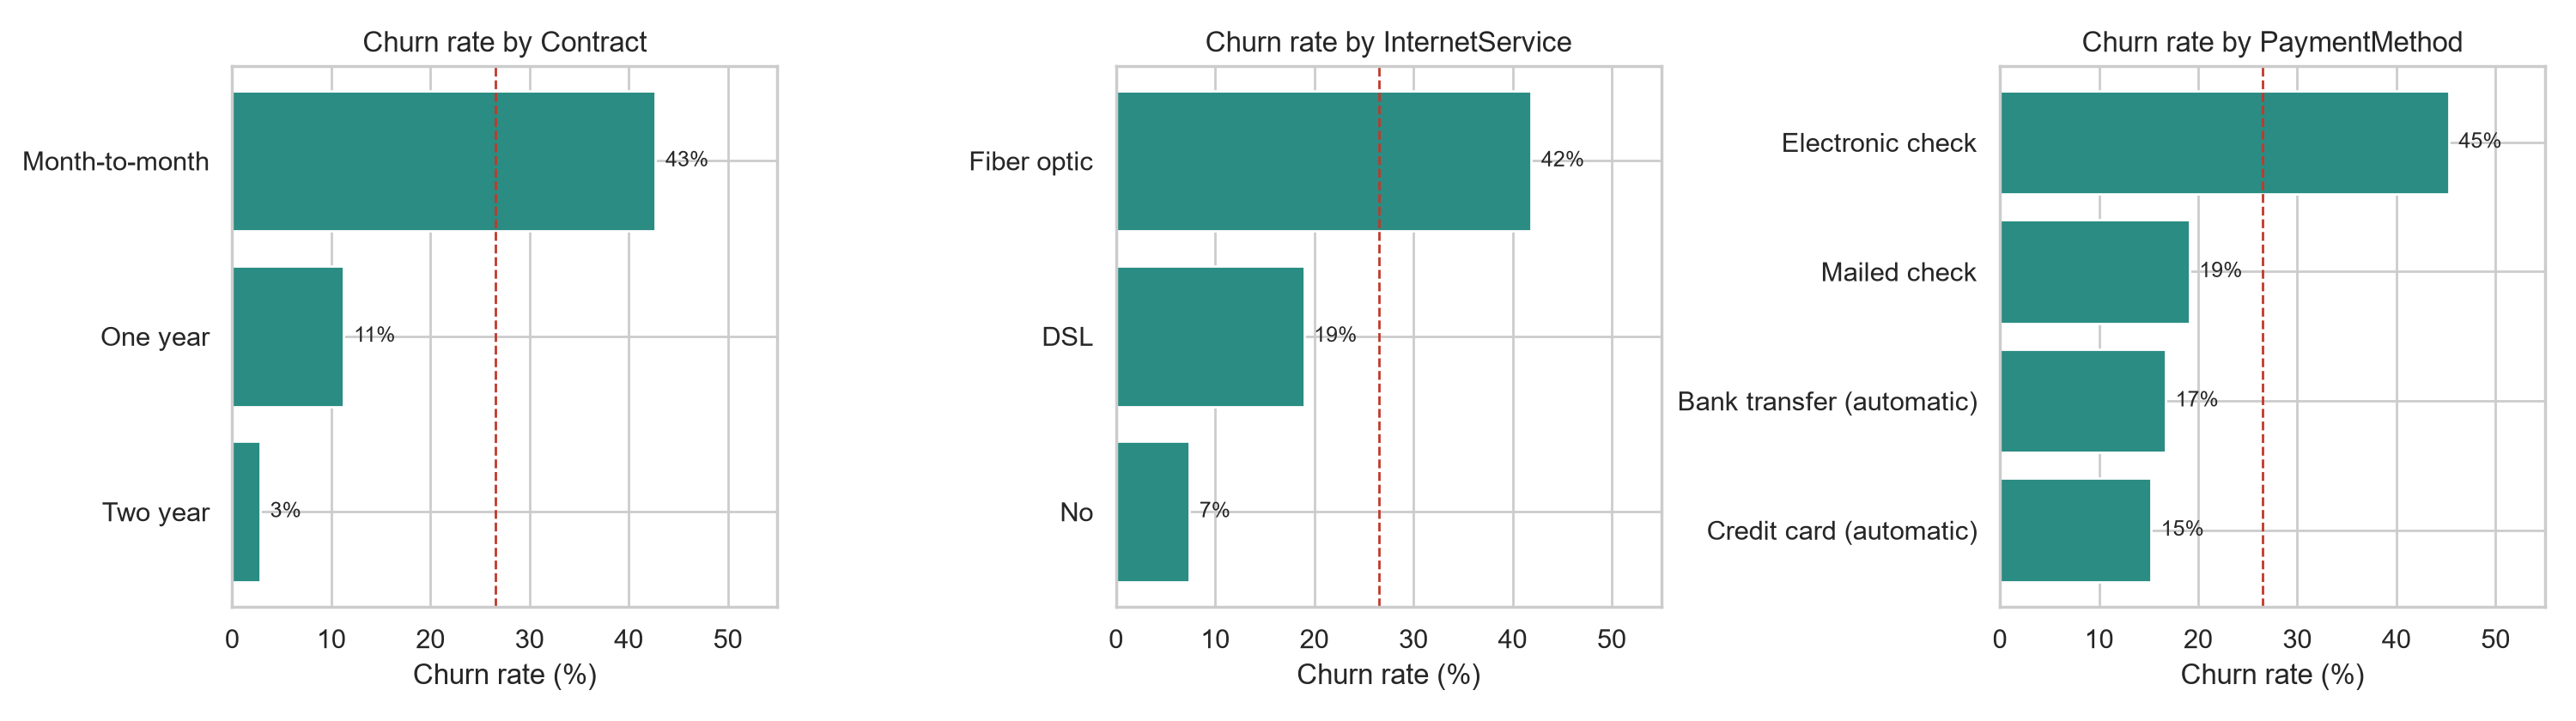

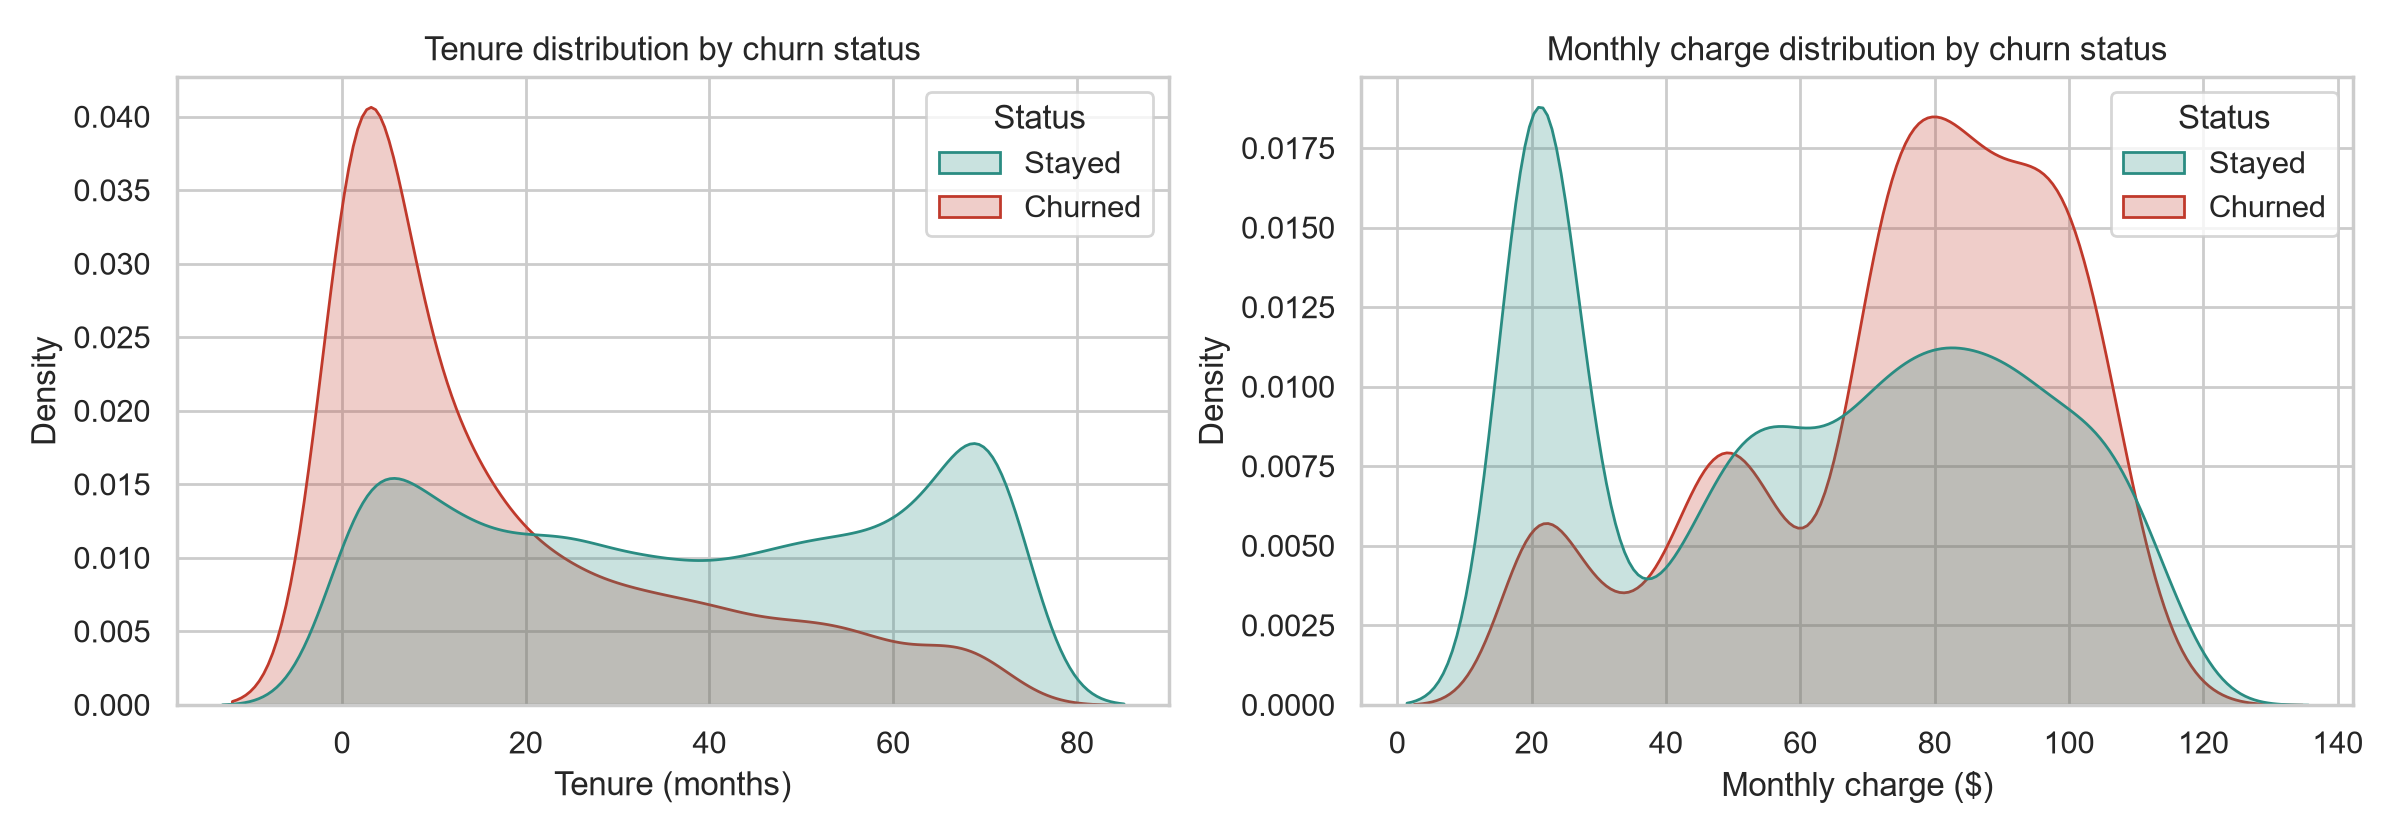

In [4]:
show('01_churn_by_category.png'); show('02_numeric_distributions.png', 750)

**19 of 22 attributes are significant after Holm correction.** The strongest are **tenure**
(r ≈ −0.48: churners have a median tenure of 10 months against 38), **contract type**
(V ≈ 0.41: 43% churn on month-to-month against 3% on two-year contracts), **no online
security or tech support** and **fiber-optic internet**. Gender, phone service and
`charge_ratio` show no association.

## 3. Predictive models (RQ1)

In [5]:
print(f"Train {M['split']['n_train']:,} / test {M['split']['n_test']:,} (stratified, churn "
      f"{M['split']['churn_rate_train']:.1%} / {M['split']['churn_rate_test']:.1%})")
pd.DataFrame({k: {"CV ROC-AUC": v["cv_roc_auc_mean"], "CV SD": v["cv_roc_auc_sd"],
                  "best hyperparameters": v["best_params"]} for k, v in M["tuning"].items()}).T

Train 5,634 / test 1,409 (stratified, churn 26.5% / 26.5%)


,CV ROC-AUC,CV SD,best hyperparameters
Dummy (majority),0.500,0.000,{}
Logistic Regression,0.846,0.012,{'C': 14.528246637516036}
Random Forest,0.848,0.010,"{'max_depth': 15, 'max_features': 0.2732229409..."
Gradient Boosting,0.846,0.010,"{'l2_regularization': 0.00998400658032865, 'le..."


In [6]:
perf = pd.DataFrame(M["test_performance"]).T
perf["ROC-AUC 95% CI"] = perf["roc_auc_ci95"].apply(lambda c: f"[{c[0]:.3f}, {c[1]:.3f}]" if isinstance(c, list) else "–")
perf[["roc_auc", "ROC-AUC 95% CI", "pr_auc", "brier", "threshold", "precision", "recall", "f1"]]

,roc_auc,ROC-AUC 95% CI,pr_auc,brier,threshold,precision,recall,f1
Dummy (majority),0.500,–,0.265,0.195,0.050,0.265,1.000,0.420
Logistic Regression,0.841,"[0.817, 0.862]",0.627,0.169,0.580,0.538,0.722,0.616
Random Forest,0.845,"[0.822, 0.866]",0.660,0.160,0.580,0.565,0.711,0.630
Gradient Boosting,0.845,"[0.821, 0.865]",0.661,0.161,0.510,0.533,0.767,0.629


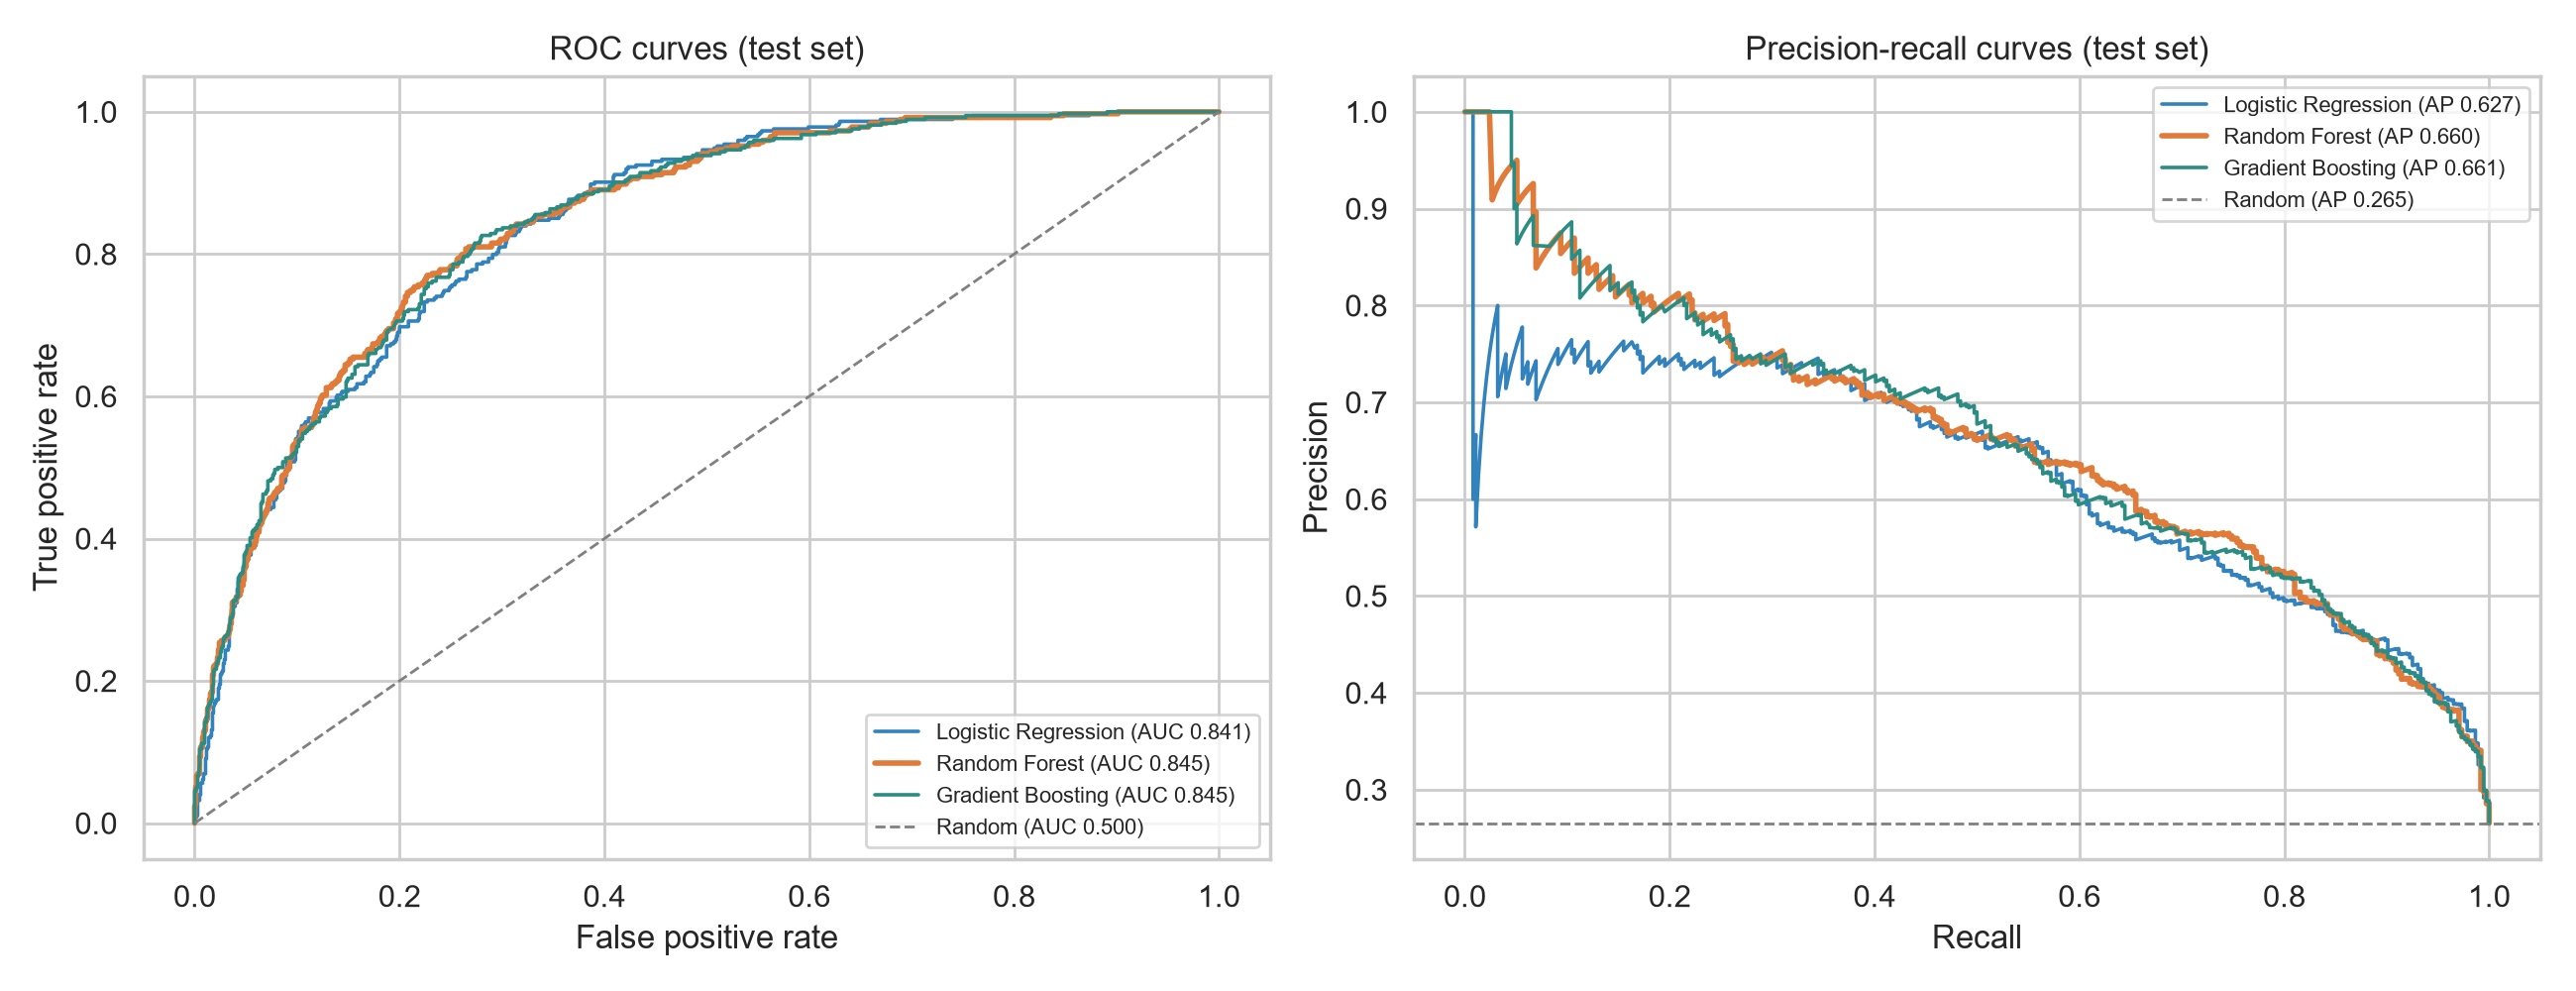

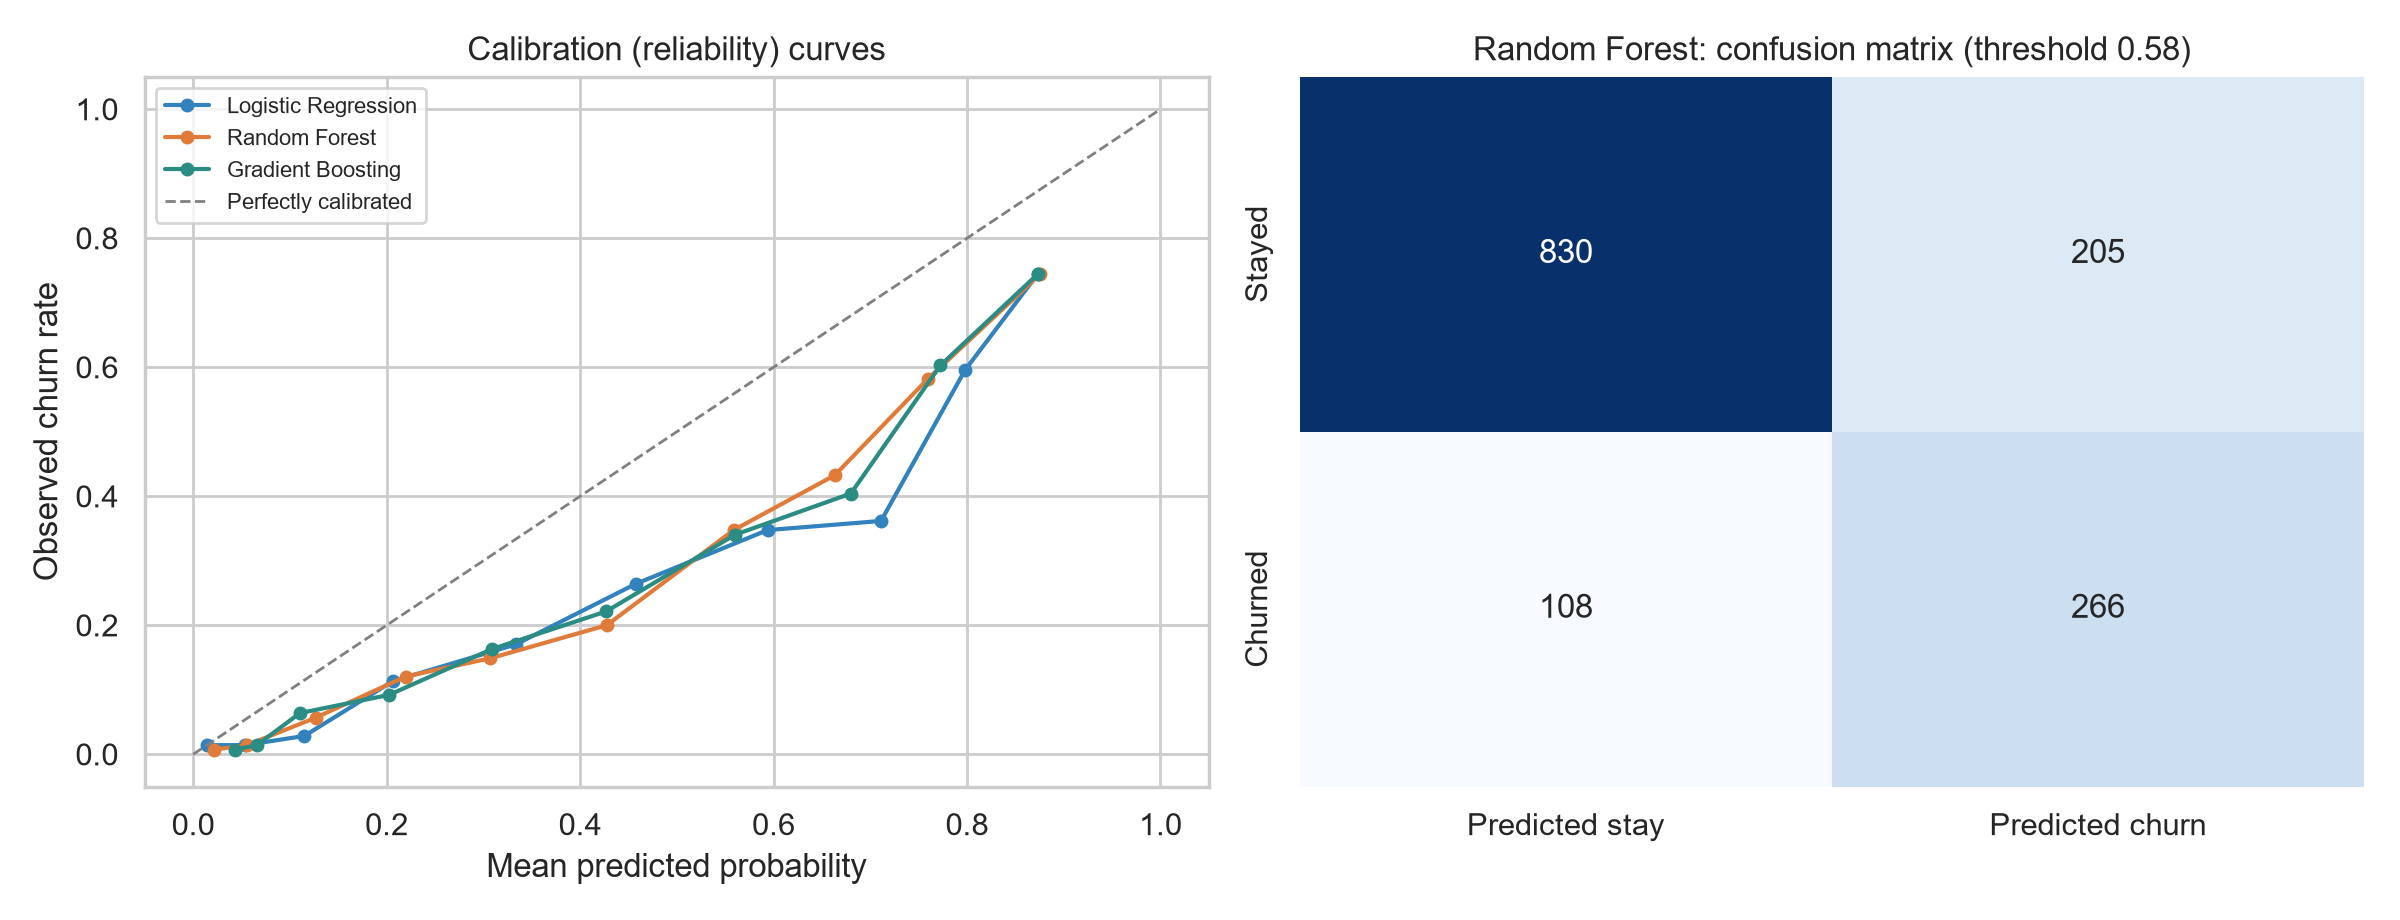

In [7]:
show('03_roc_pr.png'); show('04_calibration_confusion.png')

In [8]:
h = M["h1_selected_vs_logistic"]
print(f"Selected by CV: {M['selected_model']}")
print(f"H1  AUC({M['selected_model']}) − AUC(Logistic) = {h['diff']:+.4f}, 95% CI [{h['ci95'][0]:+.4f}, {h['ci95'][1]:+.4f}], "
      f"one-sided bootstrap p = {h['p_one_sided']:.3f}")
print(f"Top-decile lift: {M['top_decile']['lift']:.2f}× ({M['top_decile']['churn_rate']:.0%} churn among the 10% highest-risk)")

Selected by CV: Random Forest
H1  AUC(Random Forest) − AUC(Logistic) = +0.0044, 95% CI [-0.0033, +0.0124], one-sided bootstrap p = 0.127
Top-decile lift: 2.80× (74% churn among the 10% highest-risk)


**H1 is not supported.** The tuned tree ensembles reach ROC-AUC ≈ 0.845, but their advantage
over logistic regression is small and the bootstrap CI includes 0. On this tabular dataset, a
well-specified linear model is competitive. The models still rank customers very well: the top
10% highest-risk customers churn at about 2.8× the base rate.

## 4. What drives the model? (RQ2, model view)

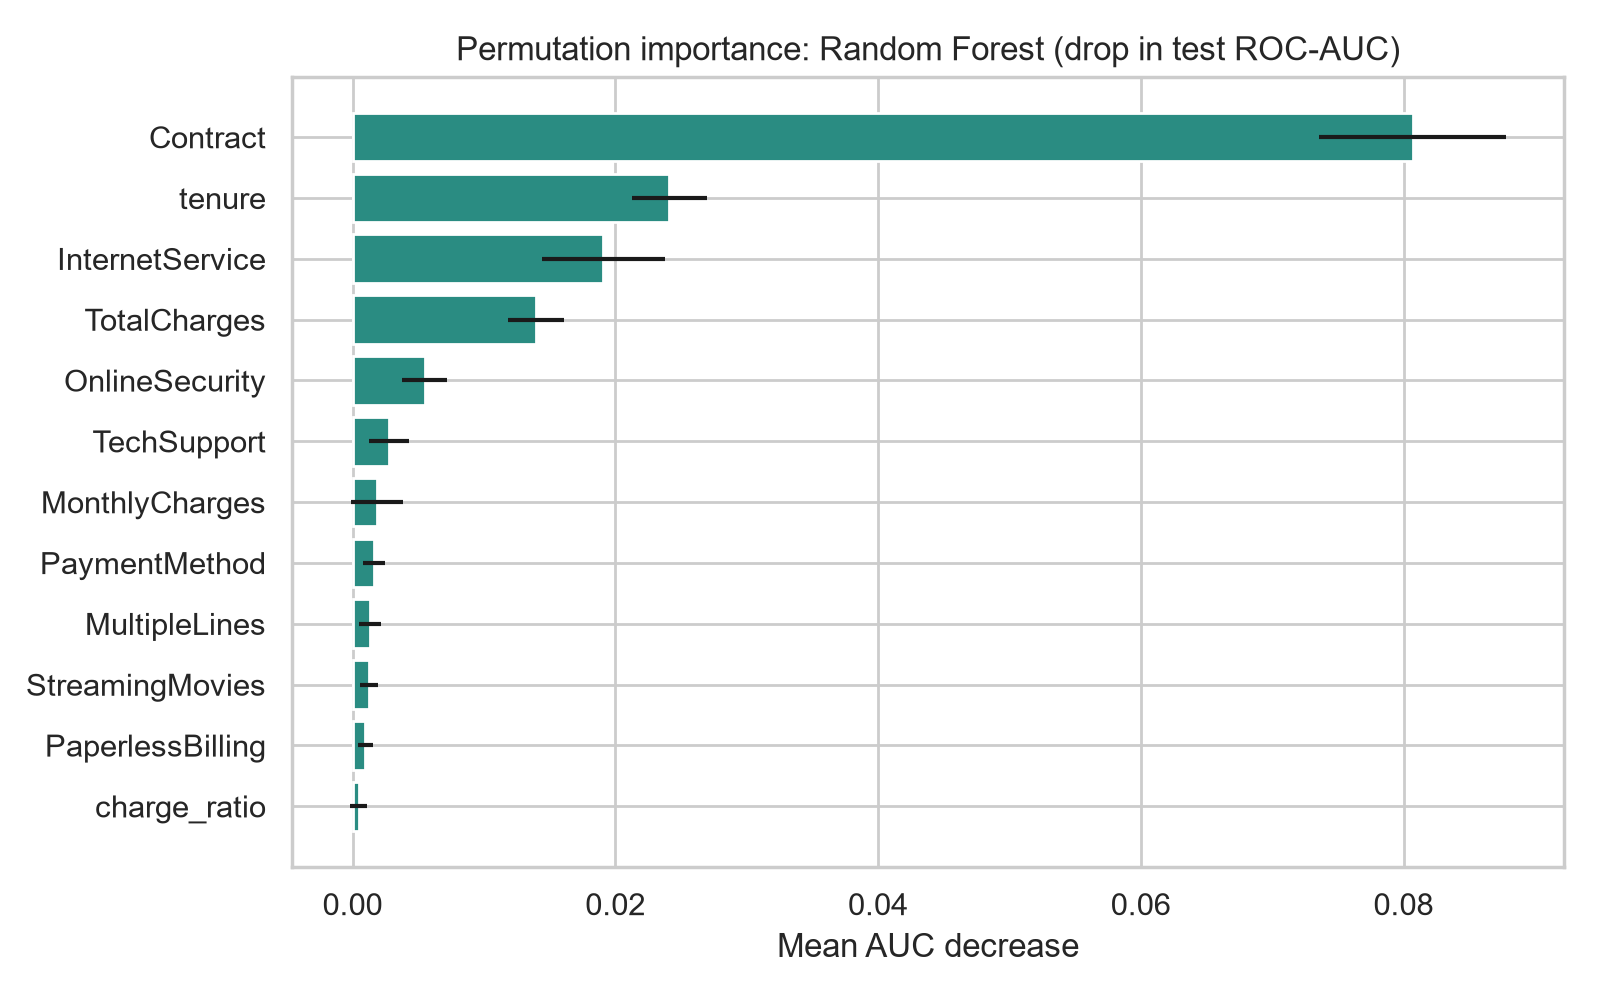

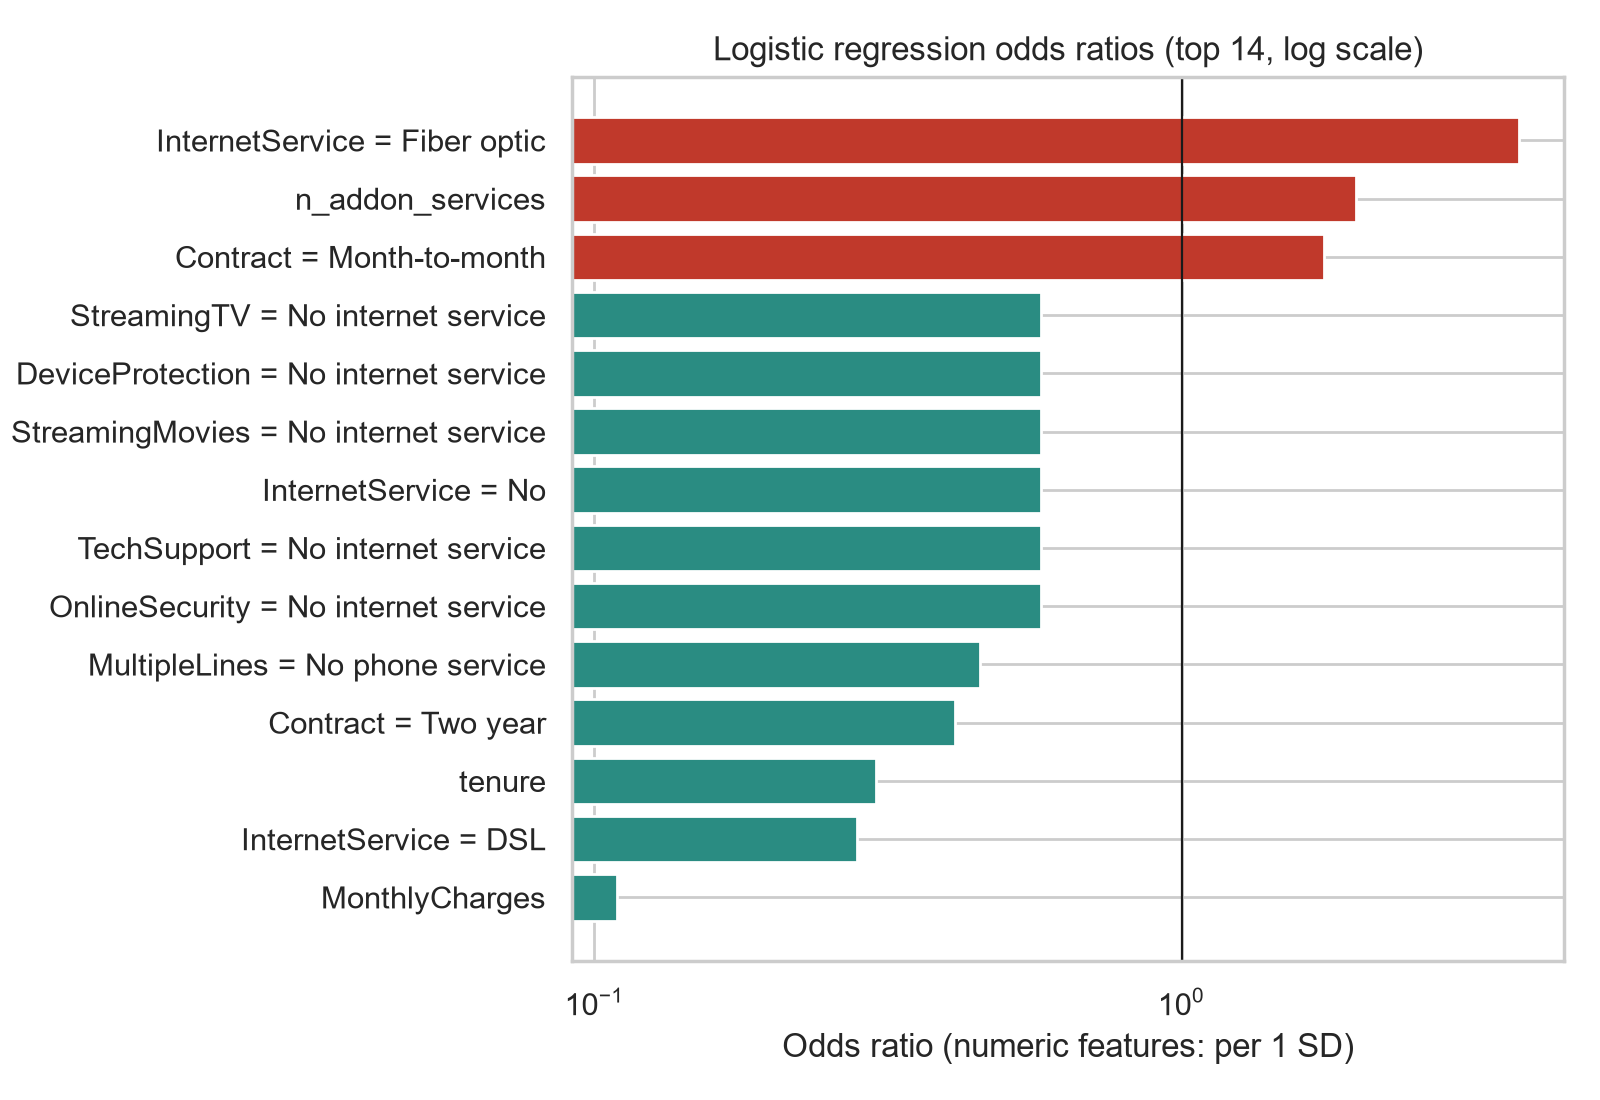

In [9]:
show('05_permutation_importance.png', 700); show('06_odds_ratios.png', 700)

Permutation importance confirms the statistical tests: **contract, tenure and internet service**
dominate. In the logistic model, the very low odds ratio for `MonthlyCharges` comes from
multicollinearity: monthly charges are largely determined by the service dummies (fiber,
add-ons). That is why the univariate tests and permutation importance are the main evidence for
RQ2.

## 5. Business value (RQ3)

In [10]:
print("Assumptions:", M["assumptions"])
b = M["business"]
print(f"Profit-maximising threshold (chosen on out-of-fold TRAIN predictions): {b['profit_threshold']:.2f}")
print(f"Test: contact {b['n_targeted_test']} of {M['split']['n_test']} customers ({b['share_targeted_test']:.0%}), "
      f"reaching {b['churners_reached']} of {b['churners_total_test']} churners")
pd.Series(b["strategies_test_profit"], name="test-set campaign profit ($)").to_frame()

Assumptions: {'contact_cost': 5.0, 'incentive_months': 1.0, 'success_rate': 0.3, 'retained_months': 12.0}
Profit-maximising threshold (chosen on out-of-fold TRAIN predictions): 0.48
Test: contact 582 of 1409 customers (41%), reaching 303 of 374 churners


,test-set campaign profit ($)
No campaign,0.000
Contact everyone,"19,677.870"
Random (same 582 customers),"8,042.140"
Logistic Regression targeting,"49,154.730"
Random Forest targeting,"50,939.615"
Perfect foresight (upper bound),"87,939.170"


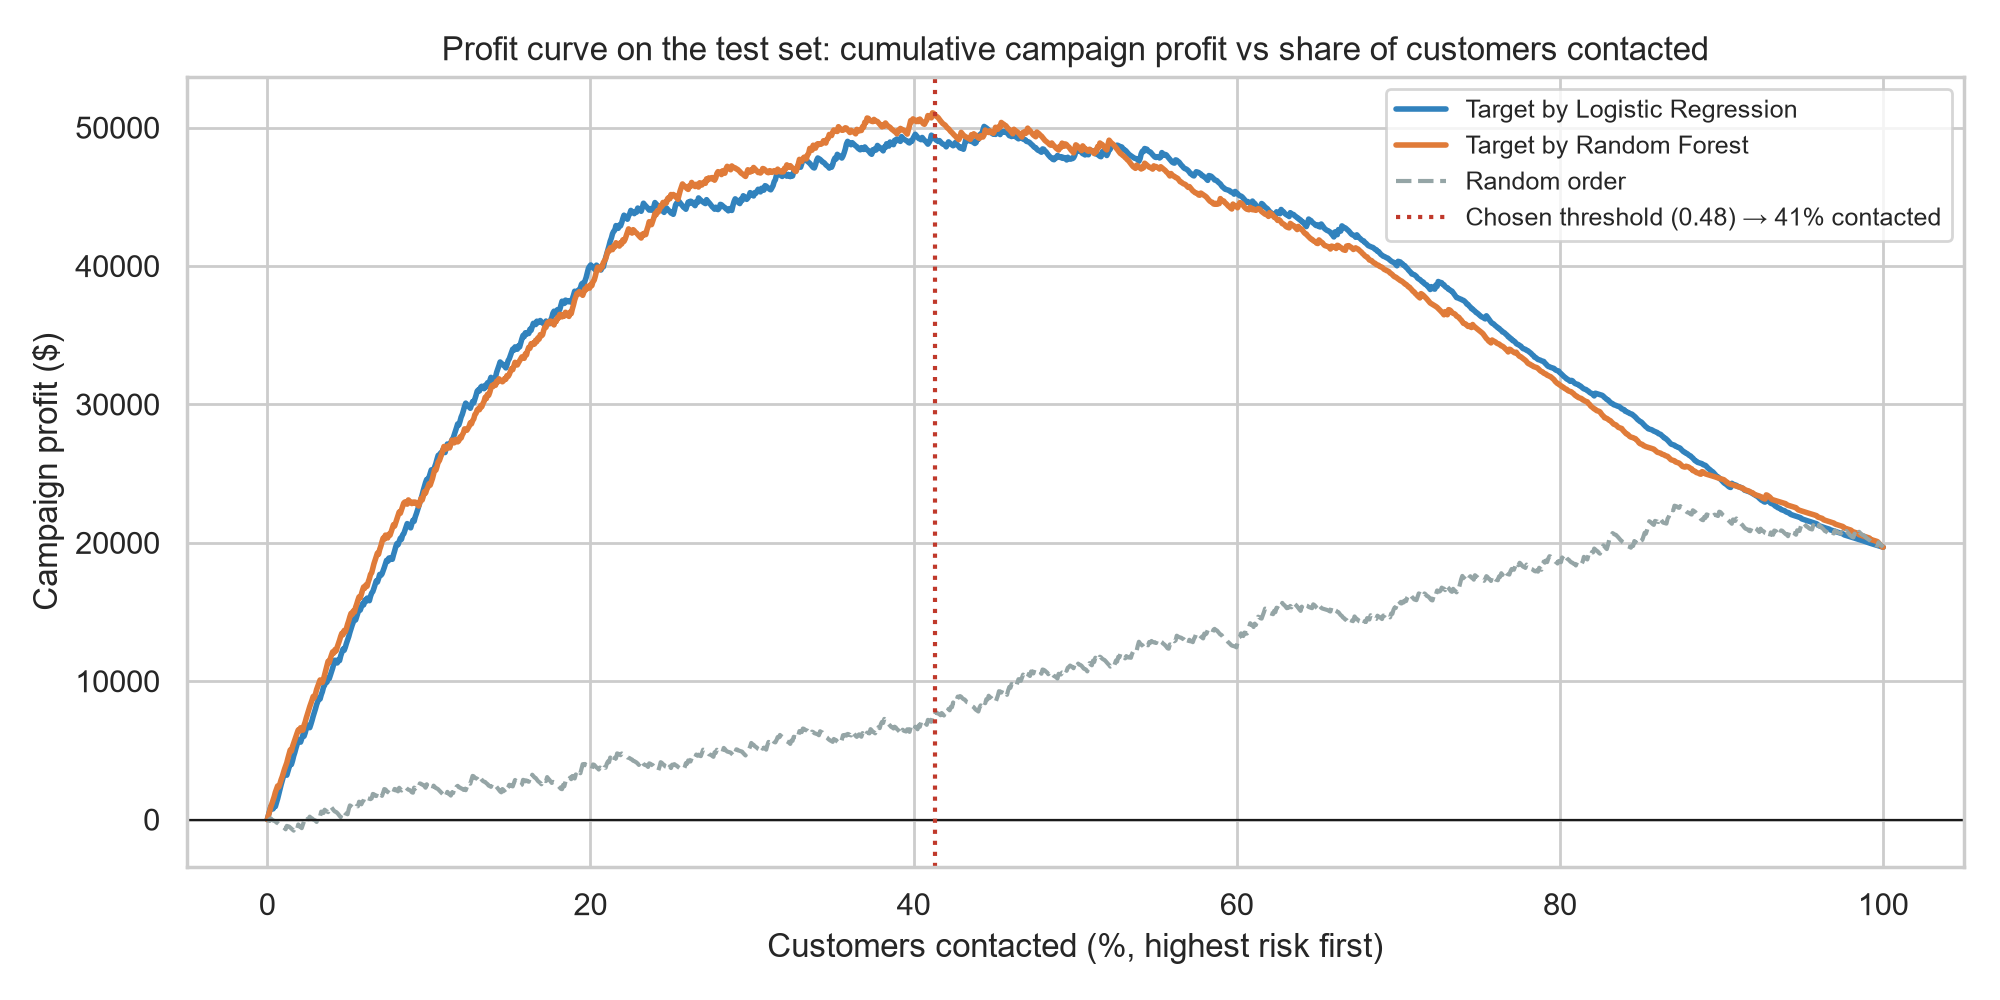

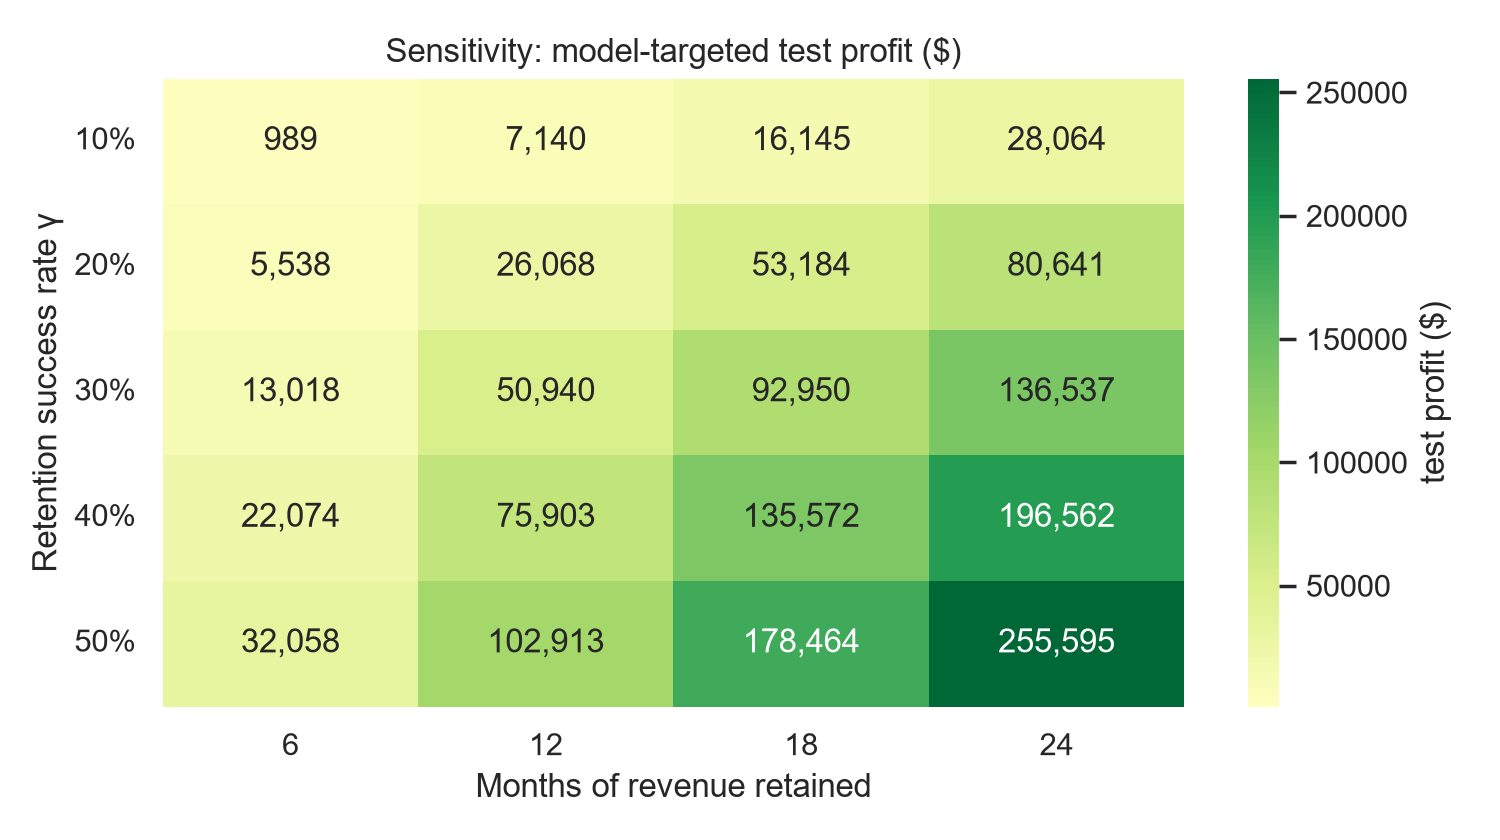

In [11]:
show('07_profit_curve.png', 850); show('08_sensitivity.png', 600)

In [12]:
sens = pd.DataFrame(M["sensitivity"])
print(f"Model targeting profitable in {(sens.model_profit > 0).sum()}/{len(sens)} scenarios; "
      f"contact-everyone loses money in {(sens.contact_all_profit < 0).sum()}/{len(sens)}.")

Model targeting profitable in 20/20 scenarios; contact-everyone loses money in 9/20.


**H3 is supported.** Under the base assumptions, model-targeted retention makes much more profit
than contacting everyone, random targeting or doing nothing. It also stays profitable across the
whole sensitivity grid, while blanket campaigns often lose money. The business recommendations
are in Section 7 of the PDF report.